# Figure2 Deterministic

Reproduces panels used in the main manuscript. Generated files are written to `logs/scripts/figure2_deterministic/`.


In [1]:
import os, sys
from pathlib import Path

if Path(os.getcwd()).stem == 'scripts':
    ROOT = Path(os.getcwd()).parent
else:
    ROOT = Path(os.getcwd())
sys.path.append(str(ROOT))
os.chdir(ROOT)
print(ROOT)


/mnt/mergerfs/yuzihan/MergedWorkSpace/33-ClimateModel/LLM-CoRe


In [ ]:
import re
import sys
import json
import yaml
import shlex
import random
import dotenv
import signal
import logging
import datetime
import nd2py as nd
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from socket import gethostname
from argparse import Namespace
from argparse import ArgumentParser
from nd2py.utils import init_logger
from setproctitle import setproctitle
from src.utils import add_negation_flags, tag2ansi, log_exception
from src.core import Triplet, Individual
from src.assistant import Assistant
from src.ai_scientist import AIScientist
from src.ai_scientist_parallel import AIScientistParallel
from src.utils import wrap_ansi

import warnings
# warnings.simplefilter('error', RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="nd2py")

dotenv.load_dotenv()
_logger = logging.getLogger('src')

args = Namespace(**json.load(open('data/cache/default_args.json', 'r')))
args.save_dir = './logs/scripts'
args.exp_name = 'figure2_deterministic'
args.train_period = ['all', 'all']
args.test_period = ['all', 'all']
args.a_skill_after_2004 = 0.0

## Build Save Path
if args.exp_name is None:
    now = datetime.now()
    date = now.strftime("%Y%m%d")
    curr = now.strftime("%H%M%S")
    host = gethostname()
    exp_name = f'{date}_{args.name}_{curr}_{host}'
    exp_name = re.compile(r'[ <>:"/\\|?*\x00-\x1f]').sub('_', exp_name.strip())
    exp_name = exp_name or 'unnamed'
    exp_name = exp_name[:255] # Max filename length on most filesystems
    args.exp_name = exp_name
save_path = Path(args.save_dir) / args.exp_name
if not save_path.exists():
    save_path.mkdir(parents=True, exist_ok=True)
else:
    _logger.warning(f"Save path {save_path} already exists.")
args.save_path = str(save_path)

## Set Random State
if args.random_state is None:
    args.random_state = random.randint(0, 2**31 - 1)
## Set Command
args.command = ' '.join(map(shlex.quote, [sys.executable, *sys.argv]))

## Init Logger
init_logger(
    "src", 
    exp_name=args.exp_name, 
    log_file=save_path / "info.log", 
    info_level='debug' if args.debug else 'info',
    show_lineno_for_all_levels=args.debug,
)
nd2py_logger = logging.getLogger("nd2py")
nd2py_logger.setLevel(_logger.level)
nd2py_logger.handlers = _logger.handlers.copy()

## Save Args
args_path = save_path / "args.json"
if args_path.exists():
    i = 1
    while args_path.with_suffix(f".json.{i}").exists(): i += 1
    args_path.rename(args_path.with_suffix(f".json.{i}"))
    _logger.warning(f"args.json already exists, backup to args.json.{i}")
_logger.note(f"Args: {args}")
with open(args_path, "w") as f:
    json.dump(vars(args), f, indent=4, ensure_ascii=False)

# Start the main process
setproctitle(f"{args.exp_name}@ZihanYu")

## Load Assistant
assistant = Assistant(args)
## Load Data
# 加载变量
variables = assistant.load_variables()
# 加载数据
df_all = assistant.load_data(normalize_co2=False)
# 划分数据
if True:
    train_start, train_end = args.train_period
    test_start, test_end = args.test_period
    train_start = pd.Period(train_start, freq='M') if train_start != 'all' else df_all.index[0]
    train_end = pd.Period(train_end, freq='M') if train_end != 'all' else df_all.index[-1]
    test_start = pd.Period(test_start, freq='M') if test_start != 'all' else df_all.index[0]
    test_end = pd.Period(test_end, freq='M') if test_end != 'all' else df_all.index[-1]
    df_train = df_all.loc[train_start:train_end]
    df_test = df_all.loc[test_start:test_end]
elif False:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
else:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=1999, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=2000, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
# 准备拓扑
edge_list, num_nodes = assistant.load_topology()
# 打印日志
_logger.info(
    f"Data loaded: {len(df_all)} samples, "
    f"where {len(df_train)}({len(df_train)/len(df_all):.2%}) "
    f"from {df_train.index[0]} to {df_train.index[-1]} for training, "
    f"and {len(df_test)}({len(df_test)/len(df_all):.2%}) "
    f"from {df_test.index[0]} to {df_test.index[-1]} for testing."
)
_logger.info(
    f"Variables: " + ", ".join(f'{var_name}({len(sub_df)})' for var_name, sub_df in df_all.T.groupby(level=0)) + "."
)
## Load Seed Individuals
seed_individuals = assistant.load_seed_individuals()

## Initialize Runner
Runner = AIScientistParallel if args.parallel else AIScientist
kwargs = dict(
    args=args,
    assistant=assistant,
    variables=variables,
    binary=[
        getattr(nd, name) for name in args.binary
        # nd.Add, nd.Sub, nd.Mul, nd.Div
    ],
    unary=[
        getattr(nd, name) for name in args.unary
        # nd.Sin, nd.Cos,
        # nd.Exp, nd.LogAbs,
        # nd.Sigmoid, nd.Tanh,
        # nd.Pow2, nd.Pow3, nd.SqrtAbs,
        # nd.Aggr, nd.Readout, nd.Sour, nd.Targ,
    ],
    edge_list=edge_list,
    num_nodes=num_nodes,
    seed_individuals=seed_individuals,
)
_logger.note(f"Initializing Runner with args: {kwargs}")
est = Runner(**kwargs)
# Set Clip Bounds
est.evaluator.simulator.set_clip_bounds(df_all, clip_factor=args.clip_factor)


Save path logs/scripts/figure2_deterministic already exists.
[figure2_deterministic|src|W|Oct15 09:16:31|0:00:00.001688] (../../../../../../tmp/ipykernel_875925/1183612455.py:84) args.json already exists, backup to args.json.6
[figure2_deterministic|src|N|Oct15 09:16:31|0:00:00.007049] Args: Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure2_deterministic', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skill=0.0, a_IOB_skill=0.0, a_SASD_skill=0.0, a_Total_skill=0.0, a_skill_after_200

In [3]:
args.a_rmse = 0.0
args.a_trajrmse = 0.0
args.a_skill_cv_sum = 0.0
args.a_skill_cv_sum_inner = 0.0
args.a_skill_cv_mean = 0.0
args.a_ENSO_skill_cv = 1.0
args.a_ATL3_skill_cv = 1.0
args.a_SASD_skill_cv = 1.0
args.a_Total_skill_cv = 10.0
args.a_skill_sum_inner = 0.0
args.a_skill_sum = 0.0
args.a_skill_mean = 0.0
args.a_ENSO_skill = 0.0
args.a_IOB_skill = 0.0
args.a_SASD_skill = 0.0
args.a_Total_skill = 0.0
args.a_skill_after_2004 = 1.0
args.a_length = 1.0
args.a_params = 0.0
args.a_std = 0.25
args.a_skewness = 0.25
args.a_spectrum = 0.25
args.a_leadlag = 0.25
args.a_forecast = 0.0
args.a_contain_co2 = 0.0
args.max_month = 40
args.a_correlation_auc_sum = 0.0
args.a_correlation_auc_cv_sum = 0.0

args.damp = 1e-1
args.atol = 1e-6
args.btol = 1e-6
args.iter_lim = None


In [4]:
baseline_indiv = assistant.load_baseline_indiv()

def evaluate3(indiv, df_test, df_train=None):
    if df_train is None:
        df_train = df_test

    # Set Ground Truth Results
    _logger.info(f"Calculating ground truth result on test data...")
    est.evaluator.set_ground_truth_result(df_test)
    # Set XRO Baseline Results
    _logger.info(f"Evaluating XRO on test data as baseline...")
    baseline_dynamics = assistant.triplet_to_dynamics(baseline_indiv.triplet)
    baseline_indiv.dynamics, mse = est.evaluator.fitter.fit_parameters(baseline_dynamics, df_train, nonlinear=True)
    est.evaluator.set_baseline_result(baseline_indiv.dynamics, df_test, use_tqdm=False)
    baseline_indiv.fitness, baseline_indiv.detail = est.evaluator.get_fitness(est.evaluator.baseline_result)
    baseline_log = est.get_log_for_indiv(baseline_indiv)
    if False:
        _logger.info(tag2ansi(f"[green]Evaluate XRO on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
        _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in baseline_log.items())))

    est.evaluator.set_fitness(indiv, df_test, df_fit=df_train, use_tqdm=False)
    log = est.get_log_for_indiv(indiv)
    _logger.info(tag2ansi(f"[green]Evaluate on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
    _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in log.items())))


In [5]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = x + mode['ENSO'] * h + log(u_co2) + aggr( sour(x) + tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x)) )
    dh_dt = h + readout(x) ** 2               + aggr( sour(x) + tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x)) )
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

if False: # set to True to use cache to skip the following code (takes around 4.5 minutes to run)
    import lzma
    import pickle

    with lzma.open("data/cache/figure2_deterministic.pkl.xz", "rb") as f:
        cache = pickle.load(f)

    detail_5fold_cv_ours = cache['detail_5fold_cv_ours']
    detail_l3yo_cv_ours = cache['detail_l3yo_cv_ours']
    detail_insample_ours = cache['detail_insample_ours']
    detail_outsample_ours = cache['detail_outsample_ours']
    detail_outsample_2004_2014_ours = cache['detail_outsample_2004_2014_ours']
    
    detail_5fold_cv_XRO = cache['detail_5fold_cv_XRO']
    detail_l3yo_cv_XRO = cache['detail_l3yo_cv_XRO']
    detail_insample_XRO = cache['detail_insample_XRO']
    detail_outsample_XRO = cache['detail_outsample_XRO']
    detail_outsample_2004_2014_XRO = cache['detail_outsample_2004_2014_XRO']
else:
    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = True
    args.use_l3yo_cv = False
    args.nfold_cv_N = 5
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_5fold_cv_ours = indiv.detail
    detail_5fold_cv_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = True
    args.lnyo_cv_N = 5
    args.lnyo_cv_N_bias = 1
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_l3yo_cv_ours = indiv.detail
    detail_l3yo_cv_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_insample_ours = indiv.detail
    detail_insample_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    evaluate3(indiv, df_all.loc['2014-01':'2024-12'], df_all.loc['1979-01':'2013-12'])
    detail_outsample_ours = indiv.detail
    detail_outsample_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    # evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.drop(df_all.loc['2004-01':'2014-12'].index))
    # evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.loc['1979-01':'2024-12'].drop(df_all.loc['2004-01':'2014-12'].index))
    evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.loc['1979-01':'2003-12'])
    # evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.loc['1979-01':'2024-12'])
    # evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.loc['1958-01':'2003-12'])
    detail_outsample_2004_2014_ours = indiv.detail
    detail_outsample_2004_2014_XRO = baseline_indiv.detail


[figure2_deterministic|data_loader|I|Oct15 09:16:49|0:00:18.266634] Normalizing AOT data by min-max scaling (min=-0.018186562, max=0.2945641)
[figure2_deterministic|data_loader|I|Oct15 09:16:49|0:00:18.276306] Normalizing TSI data by min-max scaling (min=1360.7906, max=1363.2379)
[figure2_deterministic|src|I|Oct15 09:16:49|0:00:18.326760] Calculating ground truth result on test data...
[figure2_deterministic|src|I|Oct15 09:16:55|0:00:23.508076] Evaluating XRO on test data as baseline...
[figure2_deterministic|fitness_evaluator|I|Oct15 09:17:04|0:00:33.078101] Split data into 5 folds for N-Fold CV: DatetimeIndex(['1979-01-01 00:00:00', '1988-03-08 04:48:00',
                       '1997-05-14 09:36:00', '2006-07-20 14:24:00',
                       '2015-09-25 19:12:00', '2024-12-01 00:00:00'],
                      dtype='datetime64[ns]', freq=None)
[figure2_deterministic|fitness_evaluator|I|Oct15 09:17:04|0:00:33.080039] Fold 0: 1979-01 to 1988-03
[figure2_deterministic|fitness_evalua

[figure2_deterministic|src|I|Oct15 09:17:35|0:01:04.062522] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:17:35|0:01:04.065657] Info=None from None() at Iter None
        Fitness=4.535709
        Skills=x_ENSO=32 month; x_NPMM=17 month; x_SPMM=5 month; x_IOB=29 month; x_IOD=13 month; x_SIOD=19 month; x_TNA=10 month; x_ATL3=5 month; x_SASD=5 month; h_E
        NSO=24 month; h_NPMM=23 month; h_SPMM=20 month; h_IOB=33 month; h_IOD=24 month; h_SIOD=29 month; h_TNA=15 month; h_ATL3=6 month; h_SASD=15 month;Total
         SST=135 month;Total Z20=189 month;Total=324 month
        Skills%=x_ENSO=+68.42%;x_NPMM=-5.56%;x_SPMM=+0.00%;x_IOB=+26.09%;x_IOD=+116.67%;x_SIOD=+18.75%;x_TNA=+0.00%;x_ATL3=+25.00%;x_SASD=-28.57%;h_ENSO=+41.18%;h_NPM
        M=+21.05%;h_SPMM=+25.00%;h_IOB=+106.25%;h_IOD=+118.18%;h_SIOD=+70.59%;h_TNA=+25.00%;h_ATL3=+50.00%;h_SASD=-6.25%;SST=+25.00%;Z20=+47.66%;Total=+37.29%
  

[figure2_deterministic|fitness_evaluator|W|Oct15 09:18:57|0:02:26.190420] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:20:24|0:03:53.310244] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:20:24|0:03:53.313728] Info=None from None() at Iter None
        Fitness=1.139330
        Skills=x_ENSO=32 month; x_NPMM=17 month; x_SPMM=5 month; x_IOB=29 month; x_IOD=13 month; x_SIOD=19 month; x_TNA=10 month; x_ATL3=5 month; x_SASD=5 month; h_E
        NSO=24 month; h_NPMM=23 month; h_SPMM=20 month; h_IOB=33 month; h_IOD=24 month; h_SIOD=29 month; h_TNA=15 month; h_ATL3=6 month; h_SASD=15 month;Total
         SST=135 month;Total Z20=189 month;Total=324 month
        Skills%=x_ENSO=+68.42%;x_NPMM=-5.56%;x_SPMM=+0.00%;x_IOB=+26.09%;x_IOD=+116.67%;x_SIOD=+18.75%;x_TNA=+0.00%;x_ATL3=+25.00%;x_SASD=-28.57%;h_ENSO=+41.18%;h_NPM
        M=+21.05%;h_SPMM=+25.00%;h_IOB=+106.25%;h_IOD=+118.18%;h_SIOD=+70.59%;h_TNA=+25.00%;h_ATL3=+50.00%;h_SASD=-6.25%;SST=+25.00%;Z20=+47.66%;Total=+37.29%
  

[figure2_deterministic|fitness_evaluator|W|Oct15 09:20:37|0:04:06.354566] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:20:47|0:04:15.781178] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:20:47|0:04:15.784192] Info=None from None() at Iter None
        Fitness=4.176335
        Skills=x_ENSO=32 month; x_NPMM=17 month; x_SPMM=5 month; x_IOB=29 month; x_IOD=13 month; x_SIOD=19 month; x_TNA=10 month; x_ATL3=5 month; x_SASD=5 month; h_E
        NSO=24 month; h_NPMM=23 month; h_SPMM=20 month; h_IOB=33 month; h_IOD=24 month; h_SIOD=29 month; h_TNA=15 month; h_ATL3=6 month; h_SASD=15 month;Total
         SST=135 month;Total Z20=189 month;Total=324 month
        Skills%=x_ENSO=+68.42%;x_NPMM=-5.56%;x_SPMM=+0.00%;x_IOB=+26.09%;x_IOD=+116.67%;x_SIOD=+18.75%;x_TNA=+0.00%;x_ATL3=+25.00%;x_SASD=-28.57%;h_ENSO=+41.18%;h_NPM
        M=+21.05%;h_SPMM=+25.00%;h_IOB=+106.25%;h_IOD=+118.18%;h_SIOD=+70.59%;h_TNA=+25.00%;h_ATL3=+50.00%;h_SASD=-6.25%;SST=+25.00%;Z20=+47.66%;Total=+37.29%
  

[figure2_deterministic|fitness_evaluator|W|Oct15 09:20:59|0:04:27.545567] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:21:07|0:04:36.073100] Evaluate on Test Data from 2014-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2013-12)
[figure2_deterministic|src|I|Oct15 09:21:07|0:04:36.075171] Info=None from None() at Iter None
        Fitness=0.045957
        Skills=x_ENSO=25 month; x_NPMM=9 month; x_SPMM=3 month; x_IOB=40 month; x_IOD=15 month; x_SIOD=3 month; x_TNA=5 month; x_ATL3=2 month; x_SASD=2 month; h_ENSO
        =17 month; h_NPMM=33 month; h_SPMM=12 month; h_IOB=27 month; h_IOD=23 month; h_SIOD=12 month; h_TNA=8 month; h_ATL3=1 month; h_SASD=14 month;Total SST
        =104 month;Total Z20=147 month;Total=251 month
        Skills%=x_ENSO=+47.06%;x_NPMM=-52.63%;x_SPMM=-25.00%;x_IOB=+90.48%;x_IOD=+200.00%;x_SIOD=-80.00%;x_TNA=-44.44%;x_ATL3=-33.33%;x_SASD=-50.00%;h_ENSO=+30.77%;h_
        NPMM=+26.92%;h_SPMM=-7.69%;h_IOB=+22.73%;h_IOD=+360.00%;h_SIOD=+20.00%;h_TNA=+33.33%;h_ATL3=+0.00%;h_SASD=+27.27%;SST=+7.22%;Z20=+37.38%;Total=+23.04%
      

[figure2_deterministic|fitness_evaluator|W|Oct15 09:21:19|0:04:47.823493] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:21:27|0:04:56.048967] Evaluate on Test Data from 2004-01 to 2014-12 (parameters are fitted on Train Data from 1979-01 to 2003-12)
[figure2_deterministic|src|I|Oct15 09:21:27|0:04:56.051475] Info=None from None() at Iter None
        Fitness=-4.331279
        Skills=x_ENSO=7 month; x_NPMM=7 month; x_SPMM=3 month; x_IOB=3 month; x_IOD=1 month; x_SIOD=2 month; x_TNA=4 month; x_ATL3=2 month; x_SASD=3 month; h_ENSO=5 
        month; h_NPMM=15 month; h_SPMM=13 month; h_IOB=3 month; h_IOD=2 month; h_SIOD=6 month; h_TNA=4 month; h_ATL3=2 month; h_SASD=22 month;Total SST=32 mon
        th;Total Z20=72 month;Total=104 month
        Skills%=x_ENSO=-30.00%;x_NPMM=-30.00%;x_SPMM=+0.00%;x_IOB=+0.00%;x_IOD=-66.67%;x_SIOD=-33.33%;x_TNA=-20.00%;x_ATL3=+0.00%;x_SASD=+0.00%;h_ENSO=-37.50%;h_NPMM=
        -28.57%;h_SPMM=+8.33%;h_IOB=-25.00%;h_IOD=-60.00%;h_SIOD=-53.85%;h_TNA=-33.33%;h_ATL3=+0.00%;h_SASD=-4.35%;SST=-23.81%;Z20=-23.40%;Total=-23.53%
        Skills (CV)=

In [6]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + cos(2 * t) + sin(2 * t)
    dx_dt = x + h
    dh_dt = -h - x
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)


if False: # set to True to use cache to skip the following code (takes around 3.5 minutes to run)
    import lzma
    import pickle

    with lzma.open("data/cache/figure2_deterministic.pkl.xz", "rb") as f:
        cache = pickle.load(f)

    detail_5fold_cv_RO = cache['detail_5fold_cv_RO']
    detail_l3yo_cv_RO = cache['detail_l3yo_cv_RO']
    detail_insample_RO = cache['detail_insample_RO']
    detail_outsample_RO = cache['detail_outsample_RO']
    detail_outsample_2004_2014_RO = cache['detail_outsample_2004_2014_RO']
else:
    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = True
    args.use_l3yo_cv = False
    args.nfold_cv_N = 5
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_5fold_cv_RO = indiv.detail
    # detail_5fold_cv_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = True
    args.lnyo_cv_N = 5
    args.lnyo_cv_N_bias = 1
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_l3yo_cv_RO = indiv.detail
    # detail_l3yo_cv_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_insample_RO = indiv.detail
    # detail_insample_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    evaluate3(indiv, df_all.loc['2014-01':'2024-12'], df_all.loc['1979-01':'2013-12'])
    detail_outsample_RO = indiv.detail
    # detail_outsample_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    # evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.drop(df_all.loc['2004-01':'2014-12'].index))
    evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.loc['1979-01':'2003-12'])
    detail_outsample_2004_2014_RO = indiv.detail
    # detail_outsample_XRO = baseline_indiv.detail


[figure2_deterministic|data_loader|I|Oct15 09:21:27|0:04:56.102403] Normalizing AOT data by min-max scaling (min=-0.018186562, max=0.2945641)
[figure2_deterministic|data_loader|I|Oct15 09:21:27|0:04:56.107767] Normalizing TSI data by min-max scaling (min=1360.7906, max=1363.2379)


[figure2_deterministic|src|I|Oct15 09:21:27|0:04:56.136823] Calculating ground truth result on test data...
[figure2_deterministic|src|I|Oct15 09:21:32|0:05:00.491861] Evaluating XRO on test data as baseline...


[figure2_deterministic|src|I|Oct15 09:21:59|0:05:28.322410] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:21:59|0:05:28.324629] Info=None from None() at Iter None
        Fitness=-3.971114
        Skills=x_ENSO=10 month; x_NPMM=11 month; x_SPMM=4 month; x_IOB=4 month; x_IOD=3 month; x_SIOD=4 month; x_TNA=6 month; x_ATL3=3 month; x_SASD=3 month; h_ENSO=
        13 month; h_NPMM=8 month; h_SPMM=11 month; h_IOB=7 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=8 month; h_ATL3=3 month; h_SASD=13 month;Total SST=48 m
        onth;Total Z20=73 month;Total=121 month
        Skills%=x_ENSO=-47.37%;x_NPMM=-38.89%;x_SPMM=-20.00%;x_IOB=-82.61%;x_IOD=-50.00%;x_SIOD=-75.00%;x_TNA=-40.00%;x_ATL3=-25.00%;x_SASD=-57.14%;h_ENSO=-23.53%;h_N
        PMM=-57.89%;h_SPMM=-31.25%;h_IOB=-56.25%;h_IOD=-63.64%;h_SIOD=-64.71%;h_TNA=-33.33%;h_ATL3=-25.00%;h_SASD=-18.75%;SST=-55.56%;Z20=-42.97%;Total=-48.73
        %
  

[figure2_deterministic|fitness_evaluator|W|Oct15 09:23:21|0:06:49.842096] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:24:06|0:07:34.814899] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:24:06|0:07:34.817186] Info=None from None() at Iter None
        Fitness=-3.813283
        Skills=x_ENSO=10 month; x_NPMM=11 month; x_SPMM=4 month; x_IOB=4 month; x_IOD=3 month; x_SIOD=4 month; x_TNA=6 month; x_ATL3=3 month; x_SASD=3 month; h_ENSO=
        13 month; h_NPMM=8 month; h_SPMM=11 month; h_IOB=7 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=8 month; h_ATL3=3 month; h_SASD=13 month;Total SST=48 m
        onth;Total Z20=73 month;Total=121 month
        Skills%=x_ENSO=-47.37%;x_NPMM=-38.89%;x_SPMM=-20.00%;x_IOB=-82.61%;x_IOD=-50.00%;x_SIOD=-75.00%;x_TNA=-40.00%;x_ATL3=-25.00%;x_SASD=-57.14%;h_ENSO=-23.53%;h_N
        PMM=-57.89%;h_SPMM=-31.25%;h_IOB=-56.25%;h_IOD=-63.64%;h_SIOD=-64.71%;h_TNA=-33.33%;h_ATL3=-25.00%;h_SASD=-18.75%;SST=-55.56%;Z20=-42.97%;Total=-48.73
        %
  

...

[figure2_deterministic|src|I|Oct15 09:24:24|0:07:52.527984] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:24:24|0:07:52.530285] Info=None from None() at Iter None
        Fitness=-5.478352
        Skills=x_ENSO=10 month; x_NPMM=11 month; x_SPMM=4 month; x_IOB=4 month; x_IOD=3 month; x_SIOD=4 month; x_TNA=6 month; x_ATL3=3 month; x_SASD=3 month; h_ENSO=
        13 month; h_NPMM=8 month; h_SPMM=11 month; h_IOB=7 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=8 month; h_ATL3=3 month; h_SASD=13 month;Total SST=48 m
        onth;Total Z20=73 month;Total=121 month
        Skills%=x_ENSO=-47.37%;x_NPMM=-38.89%;x_SPMM=-20.00%;x_IOB=-82.61%;x_IOD=-50.00%;x_SIOD=-75.00%;x_TNA=-40.00%;x_ATL3=-25.00%;x_SASD=-57.14%;h_ENSO=-23.53%;h_N
        PMM=-57.89%;h_SPMM=-31.25%;h_IOB=-56.25%;h_IOD=-63.64%;h_SIOD=-64.71%;h_TNA=-33.33%;h_ATL3=-25.00%;h_SASD=-18.75%;SST=-55.56%;Z20=-42.97%;Total=-48.73
        %
  

[figure2_deterministic|fitness_evaluator|W|Oct15 09:24:36|0:08:04.973108] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:24:41|0:08:09.847129] Evaluate on Test Data from 2014-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2013-12)
[figure2_deterministic|src|I|Oct15 09:24:41|0:08:09.849067] Info=None from None() at Iter None
        Fitness=-3.938000
        Skills=x_ENSO=19 month; x_NPMM=9 month; x_SPMM=6 month; x_IOB=5 month; x_IOD=4 month; x_SIOD=4 month; x_TNA=10 month; x_ATL3=2 month; x_SASD=2 month; h_ENSO=
        11 month; h_NPMM=11 month; h_SPMM=10 month; h_IOB=8 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=5 month; h_ATL3=1 month; h_SASD=8 month;Total SST=61 m
        onth;Total Z20=64 month;Total=125 month
        Skills%=x_ENSO=+11.76%;x_NPMM=-52.63%;x_SPMM=+50.00%;x_IOB=-76.19%;x_IOD=-20.00%;x_SIOD=-73.33%;x_TNA=+11.11%;x_ATL3=-33.33%;x_SASD=-50.00%;h_ENSO=-15.38%;h_N
        PMM=-57.69%;h_SPMM=-23.08%;h_IOB=-63.64%;h_IOD=-20.00%;h_SIOD=-40.00%;h_TNA=-16.67%;h_ATL3=+0.00%;h_SASD=-27.27%;SST=-37.11%;Z20=-40.19%;Total=-38.73%
        Skil

[figure2_deterministic|fitness_evaluator|W|Oct15 09:24:52|0:08:21.371592] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:24:57|0:08:26.433490] Evaluate on Test Data from 2004-01 to 2014-12 (parameters are fitted on Train Data from 1979-01 to 2003-12)
[figure2_deterministic|src|I|Oct15 09:24:57|0:08:26.435173] Info=None from None() at Iter None
        Fitness=-2.986859
        Skills=x_ENSO=6 month; x_NPMM=7 month; x_SPMM=5 month; x_IOB=2 month; x_IOD=2 month; x_SIOD=3 month; x_TNA=4 month; x_ATL3=2 month; x_SASD=2 month; h_ENSO=5 
        month; h_NPMM=8 month; h_SPMM=12 month; h_IOB=3 month; h_IOD=3 month; h_SIOD=4 month; h_TNA=6 month; h_ATL3=2 month; h_SASD=19 month;Total SST=33 mont
        h;Total Z20=62 month;Total=95 month
        Skills%=x_ENSO=-40.00%;x_NPMM=-30.00%;x_SPMM=+66.67%;x_IOB=-33.33%;x_IOD=-33.33%;x_SIOD=+0.00%;x_TNA=-20.00%;x_ATL3=+0.00%;x_SASD=-33.33%;h_ENSO=-37.50%;h_NPM
        M=-61.90%;h_SPMM=+0.00%;h_IOB=-25.00%;h_IOD=-40.00%;h_SIOD=-69.23%;h_TNA=+0.00%;h_ATL3=+0.00%;h_SASD=-17.39%;SST=-21.43%;Z20=-34.04%;Total=-30.15%
        Skills (CV)=

In [7]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + cos(2 * t) + sin(2 * t)
    dx_dt = x + h + x**2 + x*h
    dh_dt = -h - x + x**2
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

if False: # set to True to use cache to skip the following code (takes around 4 minutes to run)
    import lzma
    import pickle

    with lzma.open("data/cache/figure2_deterministic.pkl.xz", "rb") as f:
        cache = pickle.load(f)

    detail_5fold_cv_nRO = cache['detail_5fold_cv_nRO']
    detail_l3yo_cv_nRO = cache['detail_l3yo_cv_nRO']
    detail_insample_nRO = cache['detail_insample_nRO']
    detail_outsample_nRO = cache['detail_outsample_nRO']
    detail_outsample_2004_2014_nRO = cache['detail_outsample_2004_2014_nRO']
else:
    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = True
    args.use_l3yo_cv = False
    args.nfold_cv_N = 5
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_5fold_cv_nRO = indiv.detail
    # detail_5fold_cv_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = True
    args.lnyo_cv_N = 5
    args.lnyo_cv_N_bias = 1
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_l3yo_cv_nRO = indiv.detail
    # detail_l3yo_cv_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])
    detail_insample_nRO = indiv.detail
    # detail_insample_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    evaluate3(indiv, df_all.loc['2014-01':'2024-12'], df_all.loc['1979-01':'2013-12'])
    detail_outsample_nRO = indiv.detail
    # detail_outsample_XRO = baseline_indiv.detail

    args.a_skill_after_2004 = 0.0
    args.use_nfold_cv = False
    args.use_l3yo_cv = False
    # evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.drop(df_all.loc['2004-01':'2014-12'].index))
    evaluate3(indiv, df_all.loc['2004-01':'2014-12'], df_all.loc['1979-01':'2003-12'])
    detail_outsample_2004_2014_nRO = indiv.detail
    # detail_outsample_XRO = baseline_indiv.detail


[figure2_deterministic|data_loader|I|Oct15 09:24:58|0:08:26.484852] Normalizing AOT data by min-max scaling (min=-0.018186562, max=0.2945641)
[figure2_deterministic|data_loader|I|Oct15 09:24:58|0:08:26.490197] Normalizing TSI data by min-max scaling (min=1360.7906, max=1363.2379)
[figure2_deterministic|src|I|Oct15 09:24:58|0:08:26.528692] Calculating ground truth result on test data...
[figure2_deterministic|src|I|Oct15 09:25:02|0:08:31.249781] Evaluating XRO on test data as baseline...


[figure2_deterministic|src|I|Oct15 09:25:32|0:09:00.682524] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:25:32|0:09:00.684156] Info=None from None() at Iter None
        Fitness=-3.923809
        Skills=x_ENSO=13 month; x_NPMM=12 month; x_SPMM=5 month; x_IOB=4 month; x_IOD=3 month; x_SIOD=4 month; x_TNA=6 month; x_ATL3=3 month; x_SASD=3 month; h_ENSO=
        17 month; h_NPMM=8 month; h_SPMM=11 month; h_IOB=7 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=9 month; h_ATL3=3 month; h_SASD=13 month;Total SST=53 m
        onth;Total Z20=78 month;Total=131 month
        Skills%=x_ENSO=-31.58%;x_NPMM=-33.33%;x_SPMM=+0.00%;x_IOB=-82.61%;x_IOD=-50.00%;x_SIOD=-75.00%;x_TNA=-40.00%;x_ATL3=-25.00%;x_SASD=-57.14%;h_ENSO=+0.00%;h_NPM
        M=-57.89%;h_SPMM=-31.25%;h_IOB=-56.25%;h_IOD=-63.64%;h_SIOD=-64.71%;h_TNA=-25.00%;h_ATL3=-25.00%;h_SASD=-18.75%;SST=-50.93%;Z20=-39.06%;Total=-44.49%
        Skill

[figure2_deterministic|fitness_evaluator|W|Oct15 09:26:58|0:10:27.226788] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:27:51|0:11:20.088861] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:27:51|0:11:20.090671] Info=None from None() at Iter None
        Fitness=-3.754787
        Skills=x_ENSO=13 month; x_NPMM=12 month; x_SPMM=5 month; x_IOB=4 month; x_IOD=3 month; x_SIOD=4 month; x_TNA=6 month; x_ATL3=3 month; x_SASD=3 month; h_ENSO=
        17 month; h_NPMM=8 month; h_SPMM=11 month; h_IOB=7 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=9 month; h_ATL3=3 month; h_SASD=13 month;Total SST=53 m
        onth;Total Z20=78 month;Total=131 month
        Skills%=x_ENSO=-31.58%;x_NPMM=-33.33%;x_SPMM=+0.00%;x_IOB=-82.61%;x_IOD=-50.00%;x_SIOD=-75.00%;x_TNA=-40.00%;x_ATL3=-25.00%;x_SASD=-57.14%;h_ENSO=+0.00%;h_NPM
        M=-57.89%;h_SPMM=-31.25%;h_IOB=-56.25%;h_IOD=-63.64%;h_SIOD=-64.71%;h_TNA=-25.00%;h_ATL3=-25.00%;h_SASD=-18.75%;SST=-50.93%;Z20=-39.06%;Total=-44.49%
        Skill

[figure2_deterministic|fitness_evaluator|W|Oct15 09:28:04|0:11:32.847486] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:28:10|0:11:39.038248] Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure2_deterministic|src|I|Oct15 09:28:10|0:11:39.040584] Info=None from None() at Iter None
        Fitness=-5.173300
        Skills=x_ENSO=13 month; x_NPMM=12 month; x_SPMM=5 month; x_IOB=4 month; x_IOD=3 month; x_SIOD=4 month; x_TNA=6 month; x_ATL3=3 month; x_SASD=3 month; h_ENSO=
        17 month; h_NPMM=8 month; h_SPMM=11 month; h_IOB=7 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=9 month; h_ATL3=3 month; h_SASD=13 month;Total SST=53 m
        onth;Total Z20=78 month;Total=131 month
        Skills%=x_ENSO=-31.58%;x_NPMM=-33.33%;x_SPMM=+0.00%;x_IOB=-82.61%;x_IOD=-50.00%;x_SIOD=-75.00%;x_TNA=-40.00%;x_ATL3=-25.00%;x_SASD=-57.14%;h_ENSO=+0.00%;h_NPM
        M=-57.89%;h_SPMM=-31.25%;h_IOB=-56.25%;h_IOD=-63.64%;h_SIOD=-64.71%;h_TNA=-25.00%;h_ATL3=-25.00%;h_SASD=-18.75%;SST=-50.93%;Z20=-39.06%;Total=-44.49%
        Skill

[figure2_deterministic|fitness_evaluator|W|Oct15 09:28:22|0:11:50.702549] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:28:28|0:11:56.504917] Evaluate on Test Data from 2014-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2013-12)
[figure2_deterministic|src|I|Oct15 09:28:28|0:11:56.507135] Info=None from None() at Iter None
        Fitness=-4.638342
        Skills=x_ENSO=18 month; x_NPMM=6 month; x_SPMM=4 month; x_IOB=5 month; x_IOD=3 month; x_SIOD=4 month; x_TNA=9 month; x_ATL3=2 month; x_SASD=2 month; h_ENSO=1
        2 month; h_NPMM=10 month; h_SPMM=10 month; h_IOB=9 month; h_IOD=4 month; h_SIOD=6 month; h_TNA=4 month; h_ATL3=1 month; h_SASD=8 month;Total SST=53 mo
        nth;Total Z20=64 month;Total=117 month
        Skills%=x_ENSO=+5.88%;x_NPMM=-68.42%;x_SPMM=+0.00%;x_IOB=-76.19%;x_IOD=-40.00%;x_SIOD=-73.33%;x_TNA=+0.00%;x_ATL3=-33.33%;x_SASD=-50.00%;h_ENSO=-7.69%;h_NPMM=
        -61.54%;h_SPMM=-23.08%;h_IOB=-59.09%;h_IOD=-20.00%;h_SIOD=-40.00%;h_TNA=-33.33%;h_ATL3=+0.00%;h_SASD=-27.27%;SST=-45.36%;Z20=-40.19%;Total=-42.65%
        Skills (C

[figure2_deterministic|fitness_evaluator|W|Oct15 09:28:40|0:12:09.045331] (src/tools/fitness_evaluator.py:31) Refitting dynamics for individual during set_fitness.


[figure2_deterministic|src|I|Oct15 09:28:47|0:12:16.274962] Evaluate on Test Data from 2004-01 to 2014-12 (parameters are fitted on Train Data from 1979-01 to 2003-12)
[figure2_deterministic|src|I|Oct15 09:28:47|0:12:16.277204] Info=None from None() at Iter None
        Fitness=-3.439985
        Skills=x_ENSO=6 month; x_NPMM=7 month; x_SPMM=4 month; x_IOB=2 month; x_IOD=2 month; x_SIOD=3 month; x_TNA=3 month; x_ATL3=2 month; x_SASD=2 month; h_ENSO=5 
        month; h_NPMM=8 month; h_SPMM=13 month; h_IOB=3 month; h_IOD=2 month; h_SIOD=4 month; h_TNA=6 month; h_ATL3=2 month; h_SASD=19 month;Total SST=31 mont
        h;Total Z20=62 month;Total=93 month
        Skills%=x_ENSO=-40.00%;x_NPMM=-30.00%;x_SPMM=+33.33%;x_IOB=-33.33%;x_IOD=-33.33%;x_SIOD=+0.00%;x_TNA=-40.00%;x_ATL3=+0.00%;x_SASD=-33.33%;h_ENSO=-37.50%;h_NPM
        M=-61.90%;h_SPMM=+8.33%;h_IOB=-25.00%;h_IOD=-60.00%;h_SIOD=-69.23%;h_TNA=+0.00%;h_ATL3=+0.00%;h_SASD=-17.39%;SST=-26.19%;Z20=-34.04%;Total=-31.62%
        Skills (CV)=

In [ ]:
if False: # Save to cache file
    import lzma
    import pickle

    cache = {}

    cache['detail_5fold_cv_ours'] = detail_5fold_cv_ours
    cache['detail_l3yo_cv_ours'] = detail_l3yo_cv_ours
    cache['detail_insample_ours'] = detail_insample_ours
    cache['detail_outsample_ours'] = detail_outsample_ours
    cache['detail_outsample_2004_2014_ours'] = detail_outsample_2004_2014_ours

    cache['detail_5fold_cv_XRO'] = detail_5fold_cv_XRO
    cache['detail_l3yo_cv_XRO'] = detail_l3yo_cv_XRO
    cache['detail_insample_XRO'] = detail_insample_XRO
    cache['detail_outsample_XRO'] = detail_outsample_XRO
    cache['detail_outsample_2004_2014_XRO'] = detail_outsample_2004_2014_XRO

    cache['detail_5fold_cv_RO'] = detail_5fold_cv_RO
    cache['detail_l3yo_cv_RO'] = detail_l3yo_cv_RO
    cache['detail_insample_RO'] = detail_insample_RO
    cache['detail_outsample_RO'] = detail_outsample_RO
    cache['detail_outsample_2004_2014_RO'] = detail_outsample_2004_2014_RO

    cache['detail_5fold_cv_nRO'] = detail_5fold_cv_nRO
    cache['detail_l3yo_cv_nRO'] = detail_l3yo_cv_nRO
    cache['detail_insample_nRO'] = detail_insample_nRO
    cache['detail_outsample_nRO'] = detail_outsample_nRO
    cache['detail_outsample_2004_2014_nRO'] = detail_outsample_2004_2014_nRO

    with lzma.open("data/cache/figure2_deterministic.pkl.xz", "wb", preset=9) as f:
        pickle.dump(cache, f, protocol=pickle.HIGHEST_PROTOCOL)

In [8]:
df_tmp = pd.read_csv('./data/baseline/ORCA-DL/corr_201401-202312_outsample.csv')
skill_outsample_ORCA_DL = {}
for mode, group in df_tmp.sort_values(['mode', 'lead']).groupby('mode'):
    group = pd.concat([pd.DataFrame([{'corr': 1.0, 'mode': 'SASD', 'lead': 0}]), group], axis=0).sort_values(['mode', 'lead'])
    flag = (group['corr'] > 0.5) & (np.cumsum(group['corr'] > 0.5) == 1 + np.arange(len(group)))
    s = flag.to_numpy().nonzero()[0][-1]
    skill_outsample_ORCA_DL[('x', mode)] = int(group.iloc[s]["lead"])
skill_outsample_ORCA_DL = pd.Series(skill_outsample_ORCA_DL).reindex(index=detail_outsample_XRO['skill_cv'].index)
skill_outsample_ORCA_DL

x  ENSO    13.0
   NPMM    10.0
   SPMM     8.0
   IOB      8.0
   IOD      4.0
   SIOD    14.0
   TNA      3.0
   ATL3     2.0
   SASD     3.0
h  ENSO     NaN
   NPMM     NaN
   SPMM     NaN
   IOB      NaN
   IOD      NaN
   SIOD     NaN
   TNA      NaN
   ATL3     NaN
   SASD     NaN
dtype: float64

In [9]:
df_tmp = pd.read_csv('./data/baseline/ORCA-DL/corr_197901-202412_5fold.csv')
skill_5fold_cv_ORCA_DL = {}
for mode, group in df_tmp.sort_values(['mode', 'lead']).groupby('mode'):
    group = pd.concat([pd.DataFrame([{'corr': 1.0, 'mode': 'SASD', 'lead': 0}]), group], axis=0).sort_values(['mode', 'lead'])
    flag = (group['corr'] > 0.5) & (np.cumsum(group['corr'] > 0.5) == 1 + np.arange(len(group)))
    s = flag.to_numpy().nonzero()[0][-1]
    skill_5fold_cv_ORCA_DL[('x', mode)] = int(group.iloc[s]["lead"])
skill_5fold_cv_ORCA_DL = pd.Series(skill_5fold_cv_ORCA_DL).reindex(index=detail_5fold_cv_XRO['skill_cv'].index)
skill_5fold_cv_ORCA_DL

x  ENSO    11.0
   NPMM     7.0
   SPMM     3.0
   IOB     10.0
   IOD      3.0
   SIOD    12.0
   TNA      4.0
   ATL3     2.0
   SASD     3.0
h  ENSO     NaN
   NPMM     NaN
   SPMM     NaN
   IOB      NaN
   IOD      NaN
   SIOD     NaN
   TNA      NaN
   ATL3     NaN
   SASD     NaN
dtype: float64

In [10]:
df_tmp = pd.read_csv('./data/baseline/UniCM/corr_201401-202412_outsample.csv')
skill_outsample_UniCM = {}
for mode, group in df_tmp.sort_values(['mode', 'lead']).groupby('mode'):
    group = pd.concat([pd.DataFrame([{'corr': 1.0, 'mode': 'SASD', 'lead': 0}]), group], axis=0).sort_values(['mode', 'lead'])
    flag = (group['corr'] > 0.5) & (np.cumsum(group['corr'] > 0.5) == 1 + np.arange(len(group)))
    s = flag.to_numpy().nonzero()[0][-1]
    skill_outsample_UniCM[('x', mode)] = int(group.iloc[s]["lead"])
skill_outsample_UniCM = pd.Series(skill_outsample_UniCM).reindex(index=detail_outsample_XRO['skill_cv'].index)
skill_outsample_UniCM[('x', 'SASD')] = np.nan
skill_outsample_UniCM

x  ENSO    11.0
   NPMM     8.0
   SPMM     8.0
   IOB      3.0
   IOD      8.0
   SIOD     7.0
   TNA      3.0
   ATL3     2.0
   SASD     NaN
h  ENSO     NaN
   NPMM     NaN
   SPMM     NaN
   IOB      NaN
   IOD      NaN
   SIOD     NaN
   TNA      NaN
   ATL3     NaN
   SASD     NaN
dtype: float64

In [11]:
df_tmp = pd.read_csv('./data/baseline/UniCM/corr_197901-202412_5fold.csv')
skill_5fold_cv_UniCM = {}
for mode, group in df_tmp.sort_values(['mode', 'lead']).groupby('mode'):
    group = pd.concat([pd.DataFrame([{'corr': 1.0, 'mode': 'SASD', 'lead': 0}]), group], axis=0).sort_values(['mode', 'lead'])
    flag = (group['corr'] > 0.5) & (np.cumsum(group['corr'] > 0.5) == 1 + np.arange(len(group)))
    s = flag.to_numpy().nonzero()[0][-1]
    skill_5fold_cv_UniCM[('x', mode)] = int(group.iloc[s]["lead"])
skill_5fold_cv_UniCM = pd.Series(skill_5fold_cv_UniCM).reindex(index=detail_5fold_cv_XRO['skill_cv'].index)
skill_5fold_cv_UniCM

x  ENSO    6.0
   NPMM    5.0
   SPMM    3.0
   IOB     4.0
   IOD     2.0
   SIOD    4.0
   TNA     3.0
   ATL3    2.0
   SASD    0.0
h  ENSO    NaN
   NPMM    NaN
   SPMM    NaN
   IOB     NaN
   IOD     NaN
   SIOD    NaN
   TNA     NaN
   ATL3    NaN
   SASD    NaN
dtype: float64

In [12]:
df_tmp = pd.read_csv('./data/baseline/Physics-DESN/corr_201401-202401_outsample.csv')
skill_outsample_Physics_DESN = {}
for mode, group in df_tmp.sort_values(['mode', 'lead']).groupby('mode'):
    group = pd.concat([pd.DataFrame([{'corr': 1.0, 'mode': 'SASD', 'lead': 0}]), group], axis=0).sort_values(['mode', 'lead'])
    flag = (group['corr'] > 0.5) & (np.cumsum(group['corr'] > 0.5) == 1 + np.arange(len(group)))
    s = flag.to_numpy().nonzero()[0][-1]
    skill_outsample_Physics_DESN[('x', mode)] = int(group.iloc[s]["lead"])
skill_outsample_Physics_DESN = pd.Series(skill_outsample_Physics_DESN).reindex(index=detail_outsample_XRO['skill_cv'].index)
skill_outsample_Physics_DESN

x  ENSO    11.0
   NPMM     5.0
   SPMM     4.0
   IOB     13.0
   IOD      3.0
   SIOD     6.0
   TNA      3.0
   ATL3     2.0
   SASD     2.0
h  ENSO     NaN
   NPMM     NaN
   SPMM     NaN
   IOB      NaN
   IOD      NaN
   SIOD     NaN
   TNA      NaN
   ATL3     NaN
   SASD     NaN
dtype: float64

In [23]:
df_tmp = pd.read_csv('./data/baseline/Physics-DESN/corr_197901-202412_5fold.csv')
skill_5fold_cv_Physics_DESN = {}
for mode, group in df_tmp.sort_values(['mode', 'lead']).groupby('mode'):
    group = pd.concat([pd.DataFrame([{'corr': 1.0, 'mode': 'SASD', 'lead': 0}]), group], axis=0).sort_values(['mode', 'lead'])
    flag = (group['corr'] > 0.5) & (np.cumsum(group['corr'] > 0.5) == 1 + np.arange(len(group)))
    s = flag.to_numpy().nonzero()[0][-1]
    skill_5fold_cv_Physics_DESN[('x', mode)] = int(group.iloc[s]["lead"])
skill_5fold_cv_Physics_DESN = pd.Series(skill_5fold_cv_Physics_DESN).reindex(index=detail_5fold_cv_XRO['skill_cv'].index)
skill_5fold_cv_Physics_DESN

x  ENSO    13.0
   NPMM     4.0
   SPMM     2.0
   IOB     13.0
   IOD      2.0
   SIOD     5.0
   TNA      3.0
   ATL3     2.0
   SASD     2.0
h  ENSO     NaN
   NPMM     NaN
   SPMM     NaN
   IOB      NaN
   IOD      NaN
   SIOD     NaN
   TNA      NaN
   ATL3     NaN
   SASD     NaN
dtype: float64

In [14]:
save_dir = Path(args.save_path)
save_dir.mkdir(parents=True, exist_ok=True)

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Optional


def get_skill(s, target=0.5):
    cross_idx = (s <= target).to_numpy().argmax()
    x1, y1 = s.index[cross_idx - 1], s.iloc[cross_idx - 1]
    x2, y2 = s.index[cross_idx], s.iloc[cross_idx]
    return x1 + (target - y1) / (y2 - y1) * (x2 - x1)


def map_value(x):
    x = np.asarray(x, dtype=float)
    # y = np.where(
    #     x <= 10, 
    #     x * 2,
    #     20 + (x - 10) * (20 / 30)
    # )
    # y = np.sqrt(x / 40)
    y = (x / 40) ** (np.log(0.5) / np.log(10/40))
    return y.item() if np.isscalar(x) else y

def radarplot(
    data: pd.DataFrame,
    x: str,
    y: str,
    hue: Optional[str] = None,
    style: Optional[str] = None,
    palette: Optional[List[str]] = None,
    ax: Optional[plt.Axes] = None,
    order: Optional[List[str]] = None,
    hue_order: Optional[List[str]] = None,
    map_value=None,
    lw={}
):
    """
    Seaborn 风格的雷达图绘制函数。
    """
    # 1. 确定 X 轴的分类（雷达图的顶点）及其顺序
    if order is None:
        categories = data[x].unique().tolist()
    else:
        categories = order
        
    N = len(categories)
    
    # 2. 计算极坐标的角度并闭合（首尾相连）
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]
    
    # 3. 确定 Hue 分组及颜色
    if hue is not None:
        if hue_order is None:
            hues = data[hue].unique().tolist()
        else:
            hues = hue_order
        colors = sns.color_palette(palette, n_colors=len(hues))
    else:
        hues = [None]
        # 如果没有传入 hue，但传入了 palette，取第一个颜色，否则用默认颜色
        colors = [sns.color_palette(palette)[0] if palette else sns.color_palette()[0]]

    # 4. 确定 Style 分组及线型
    line_styles = ['-', '--', ':', '-.']
    style_dict = {}
    if style is not None:
        styles = data[style].unique().tolist()
        style_dict = {s: line_styles[i % len(line_styles)] for i, s in enumerate(styles)}

    # 5. 初始化极坐标系 Axe
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(projection='polar'))
    elif ax.name != 'polar':
        raise ValueError("传入的 ax 必须是极坐标系 (projection='polar')！")

    # 6. 遍历分组进行绘制
    for i, h in enumerate(hues):
        # 筛选数据
        if h is None:
            subset = data
        else:
            subset = data[data[hue] == h]
            
        # 聚合数据（类似 sns.lineplot，处理同分类下有多个值的情况，默认取均值）
        agg_data = subset.groupby(x)[y].mean().reindex(categories).fillna(0)
        values = agg_data.tolist()
        if map_value is not None:
            values = map_value(values).tolist()
        values += values[:1] # 闭合数据点
        
        # 确定线型 (如果 style 参数和 hue 绑定，或者单独指定)
        current_ls = '-'
        if style is not None:
            # 简单起见，取该 subset 中出现频率最高的 style
            dominant_style = subset[style].mode().iloc[0]
            current_ls = style_dict.get(dominant_style, '-')

        # 绘制线条与填充
        label_name = str(h) if h is not None else None
        current_lw = lw.get(h, 1) if isinstance(lw, dict) else lw
        ax.plot(angles, values, color=colors[i], linestyle=current_ls, label=label_name, lw=current_lw)
        ax.fill(angles, values, color=colors[i], alpha=0.2)

    # 7. 美化图表
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories)
    
    # 隐藏最外层的圆圈边框 (可选，让图表更清爽)
    # ax.spines['polar'].set_visible(False)
    
    # 调整图例位置，避免遮挡图表
    # if hue is not None:
    #     ax.legend(title=hue, loc='upper right', bbox_to_anchor=(1.3, 1.1))
        
    return ax


Total Skill Improvement: 37.29% (236 -> 324)
SST Skill Improvement: nan% (0 -> 0)
OHC Skill Improvement: nan% (0 -> 0)
Total Skill Improvement: 42.55% (188 -> 268)
SST Skill Improvement: nan% (0 -> 0)
OHC Skill Improvement: nan% (0 -> 0)
Total Skill Improvement: 23.04% (204 -> 251)
SST Skill Improvement: nan% (0 -> 0)
OHC Skill Improvement: nan% (0 -> 0)


/tmp/ipykernel_875925/4108328967.py:49: RuntimeWarning: invalid value encountered in scalar divide
  print(f"SST Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
/tmp/ipykernel_875925/4108328967.py:52: RuntimeWarning: invalid value encountered in scalar divide
  print(f"OHC Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
/tmp/ipykernel_875925/4108328967.py:96: RuntimeWarning: invalid value encountered in scalar divide
  print(f"SST Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
/tmp/ipykernel_875925/4108328967.py:99: RuntimeWarning: invalid value encountered in scalar divide
  print(f"OHC Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
/tmp/ipykernel_875925/4108328967.py:150: RuntimeWarning: invalid value encountered in scalar divide
  print(f"SST Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
/tmp/ipykernel_875925/4108328967.py:153: RuntimeWarning: invalid value encountered in scalar divide
  print(f"OHC Skill Improvement: {

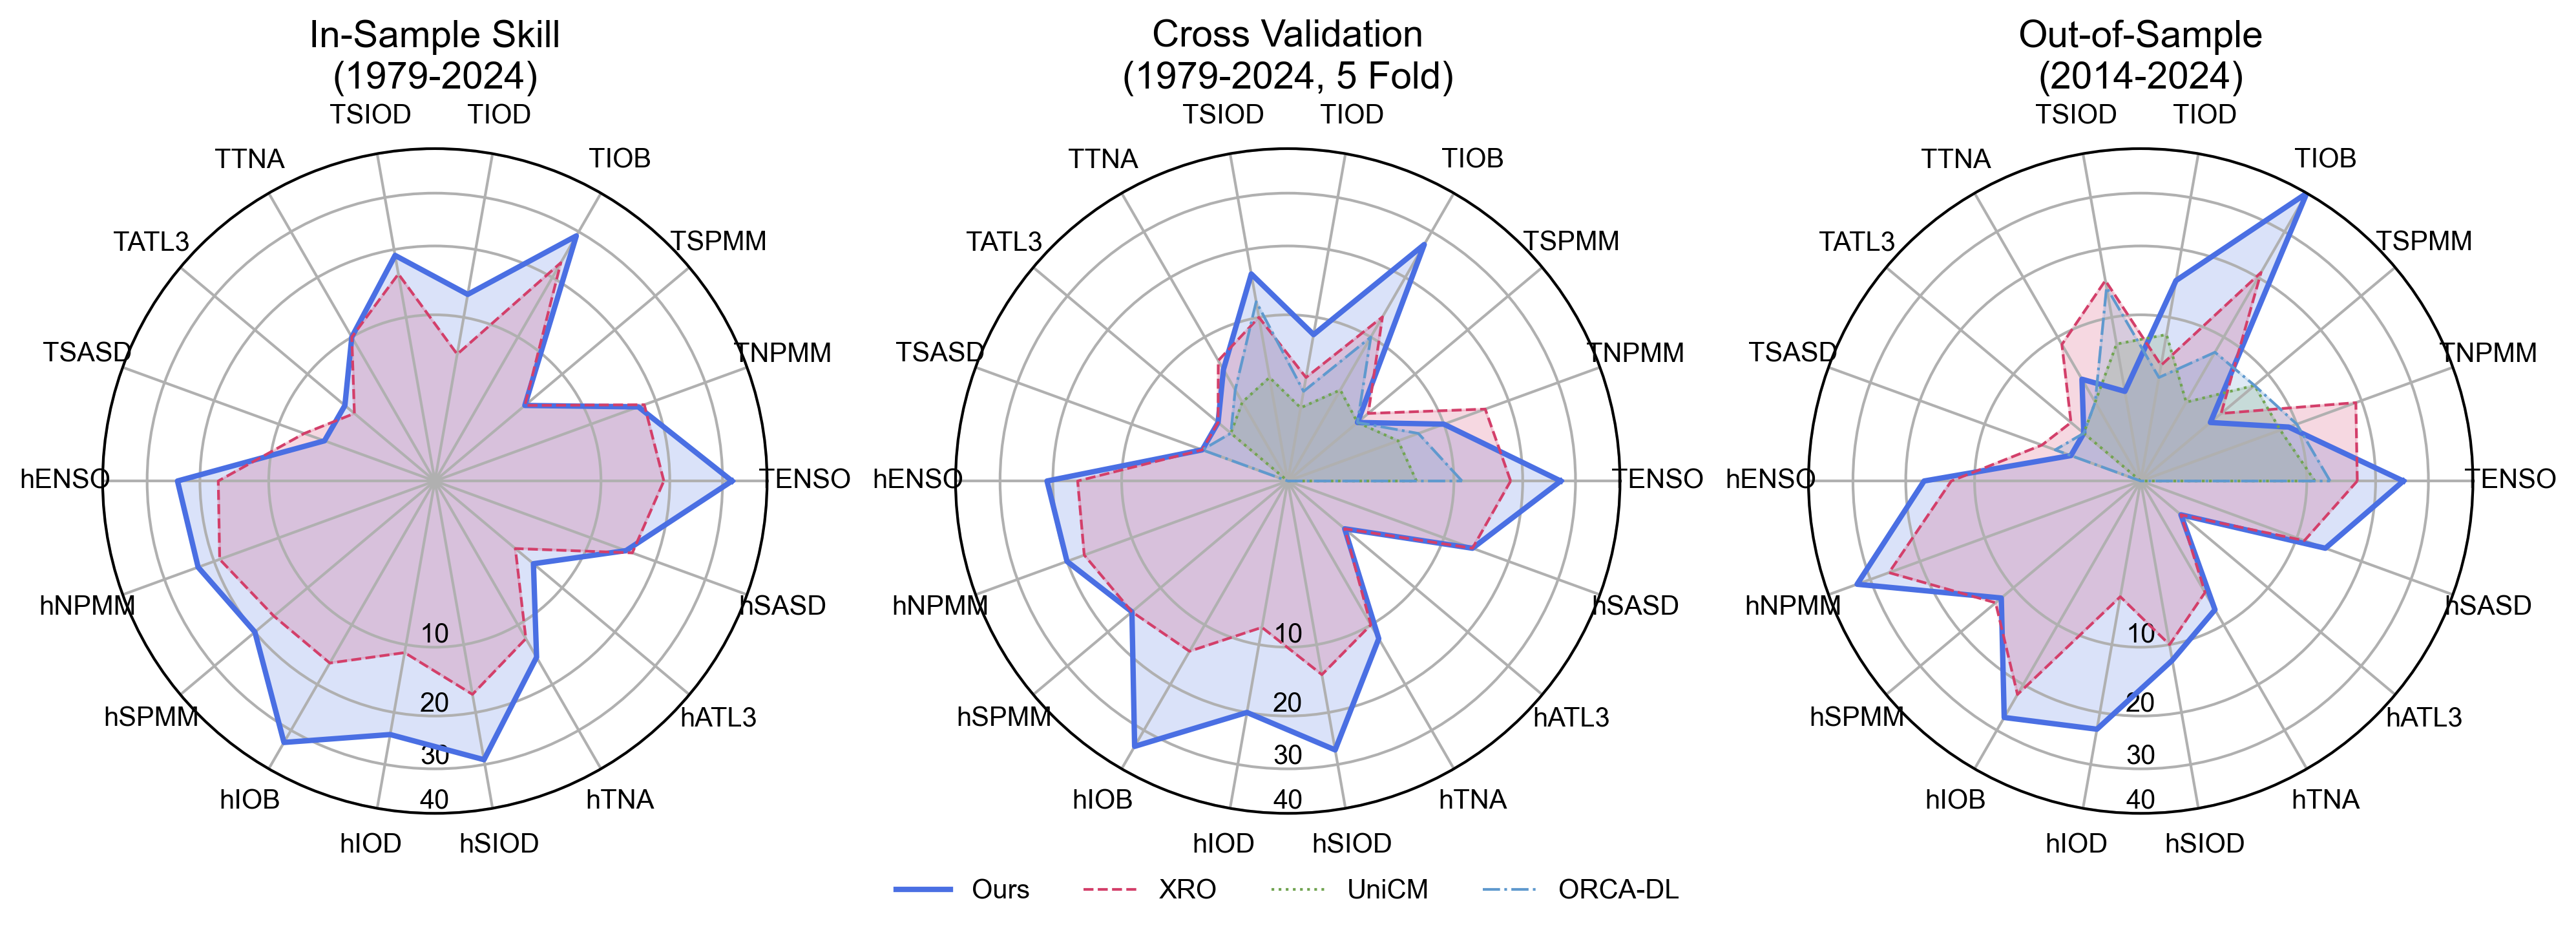

In [16]:
from nd2py.utils.plot import get_fig, plt
import seaborn as sns
import pandas as pd


fi, fig, axes = get_fig(1, 3, FW=36, A_ratio=1.0, LM=5, RM=5, TM=5, BM=5, HS=5, VS=3, dpi=300, fontsize=14, lw=1)
ax_loader = iter(axes)

tmp = {'x':'T'}
# var_format = lambda x: f'${x[0]}_{{{x[1]}}}$'
var_format = lambda x: f'{tmp.get(x[0], x[0])}{x[1]}'

if True: ## In-Sample
    ax = next(ax_loader)
    ax_polar = fig.add_axes(ax.get_position(), projection='polar', label='polar_ax')
    ax.set_visible(False)
    ax = ax_polar

    skill_RO = detail_insample_RO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_nRO = detail_insample_nRO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_XRO = detail_insample_XRO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_ours = detail_insample_ours['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))

    df_plot = (
        pd.DataFrame({
            'Ours': skill_ours,
            # 'RO': skill_RO,
            # 'nRO': skill_nRO,
            'XRO': skill_XRO,
        })
        .rename_axis('Mode')
        .reset_index()
    )
    df_plot2 = df_plot.melt(id_vars='Mode', var_name='Model', value_name='Skill')
    radarplot(data=df_plot2, x='Mode', y='Skill', hue='Model', ax=ax, style='Model', map_value=map_value, palette=['#4a6fe3', '#d33f6a', '#71a451', '#5f99ce', '#c57b3e'], lw={'Ours': 2})
    ax.set_rlabel_position(270)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks(map_value([10, 20, 30, 40]))
    ax.set_yticklabels([10, 20, 30, 40], ha='center', va='bottom')
    ax.set_ylim(*map_value([0, 40]))
    ax.set_title("In-Sample Skill\n(1979-2024)")
    
    ours = df_plot["Ours"].sum()
    xro = df_plot['XRO'].sum()
    print(f"Total Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
    ours = df_plot[df_plot['Mode'].str.contains('x_')]['Ours'].sum()
    xro = df_plot[df_plot['Mode'].str.contains('x_')]['XRO'].sum()
    print(f"SST Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
    ours = df_plot[df_plot['Mode'].str.contains('h_')]['Ours'].sum()
    xro = df_plot[df_plot['Mode'].str.contains('h_')]['XRO'].sum()
    print(f"OHC Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")

if True: ## 5Fold-CV
    ax = next(ax_loader)
    ax_polar = fig.add_axes(ax.get_position(), projection='polar', label='polar_ax')
    ax.set_visible(False)
    ax = ax_polar

    skill_RO = detail_5fold_cv_RO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_nRO = detail_5fold_cv_nRO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_XRO = detail_5fold_cv_XRO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_ours = detail_5fold_cv_ours['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_UniCM = skill_5fold_cv_UniCM.copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_ORCA_DL = skill_5fold_cv_ORCA_DL.copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_Physics_DESN = skill_5fold_cv_Physics_DESN.copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))

    df_plot = (
        pd.DataFrame({
            'Ours': skill_ours,
            # 'RO': skill_RO,
            # 'nRO': skill_nRO,
            'XRO': skill_XRO,
            'UniCM': skill_UniCM,
            'ORCA-DL': skill_ORCA_DL,
            # 'Physics-DESN': skill_Physics_DESN,
        })
        .rename_axis('Mode')
        .reset_index()
    )
    df_plot2 = df_plot.melt(id_vars='Mode', var_name='Model', value_name='Skill')
    radarplot(data=df_plot2, x='Mode', y='Skill', hue='Model', ax=ax, style='Model', map_value=map_value, palette=['#4a6fe3', '#d33f6a', '#71a451', '#5f99ce', '#c57b3e'], lw={'Ours': 2})
    ax.set_rlabel_position(270)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks(map_value([10, 20, 30, 40]))
    ax.set_yticklabels([10, 20, 30, 40], ha='center', va='bottom')
    ax.set_ylim(*map_value([0, 40]))
    ax.set_title('Cross Validation\n(1979-2024, 5 Fold)')
    
    ours = df_plot["Ours"].sum()
    xro = df_plot['XRO'].sum()
    print(f"Total Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
    ours = df_plot[df_plot['Mode'].str.contains('x_')]['Ours'].sum()
    xro = df_plot[df_plot['Mode'].str.contains('x_')]['XRO'].sum()
    print(f"SST Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
    ours = df_plot[df_plot['Mode'].str.contains('h_')]['Ours'].sum()
    xro = df_plot[df_plot['Mode'].str.contains('h_')]['XRO'].sum()
    print(f"OHC Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")

if True: ## Out-Sample (2014-2024)
    ax = next(ax_loader)
    ax_polar = fig.add_axes(ax.get_position(), projection='polar', label='polar_ax')
    ax.set_visible(False)
    ax = ax_polar

    skill_RO = detail_outsample_RO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_nRO = detail_outsample_nRO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_XRO = detail_outsample_XRO['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_ours = detail_outsample_ours['skill_cv'].copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_UniCM = skill_outsample_UniCM.copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_ORCA_DL = skill_outsample_ORCA_DL.copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))
    skill_Physics_DESN = skill_outsample_Physics_DESN.copy().pipe(lambda x: x.set_axis(x.index.map(var_format)))

    df_plot = (
        pd.DataFrame({
            'Ours': skill_ours,
            # 'RO': skill_RO,
            # 'nRO': skill_nRO,
            'XRO': skill_XRO,
            'UniCM': skill_UniCM,
            'ORCA-DL': skill_ORCA_DL,
            # 'Physics-DESN': skill_Physics_DESN,
        })
        .rename_axis('Mode')
        .reset_index()
    )
    df_plot2 = df_plot.melt(id_vars='Mode', var_name='Model', value_name='Skill')
    radarplot(data=df_plot2, x='Mode', y='Skill', hue='Model', ax=ax, style='Model', map_value=map_value, palette=['#4a6fe3', '#d33f6a', '#71a451', '#5f99ce', '#c57b3e'], lw={'Ours': 2})
    ax.set_rlabel_position(270)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks(map_value([10, 20, 30, 40]))
    ax.set_yticklabels([10, 20, 30, 40], ha='center', va='bottom')
    ax.set_ylim(*map_value([0, 40]))
    ax.set_title('Out-of-Sample\n(2014-2024)')
    # ax.legend_.remove()
    x, y, w, h = fi['bottom_box']
    fig.legend(
        *ax.get_legend_handles_labels(),
        loc='upper center', bbox_to_anchor=(x, y-0.04, w, h),
        title="", ncols=5, frameon=False
    )

    ours = df_plot["Ours"].sum()
    xro = df_plot['XRO'].sum()
    print(f"Total Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
    ours = df_plot[df_plot['Mode'].str.contains('x_')]['Ours'].sum()
    xro = df_plot[df_plot['Mode'].str.contains('x_')]['XRO'].sum()
    print(f"SST Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")
    ours = df_plot[df_plot['Mode'].str.contains('h_')]['Ours'].sum()
    xro = df_plot[df_plot['Mode'].str.contains('h_')]['XRO'].sum()
    print(f"OHC Skill Improvement: {ours / xro - 1:.2%} ({xro} -> {ours})")

fig.savefig(save_dir / 'Fig2a-c-e.svg', transparent=True, dpi=300)
fig.savefig(save_dir / 'Fig2a-c-e.png', transparent=True, dpi=300)
fig.savefig(save_dir / 'Fig2a-c-e.pdf', transparent=True, dpi=300)


In [30]:
def get_skill(s, target=0.5):
    cross_idx = (s <= target).to_numpy().argmax()
    x1, y1 = s.index[cross_idx - 1], s.iloc[cross_idx - 1]
    x2, y2 = s.index[cross_idx], s.iloc[cross_idx]
    skill = x1 + (target - y1) / (y2 - y1) * (x2 - x1)
    return np.clip(skill, 0, len(s) - 1)  # 确保 skill 不超过索引范围

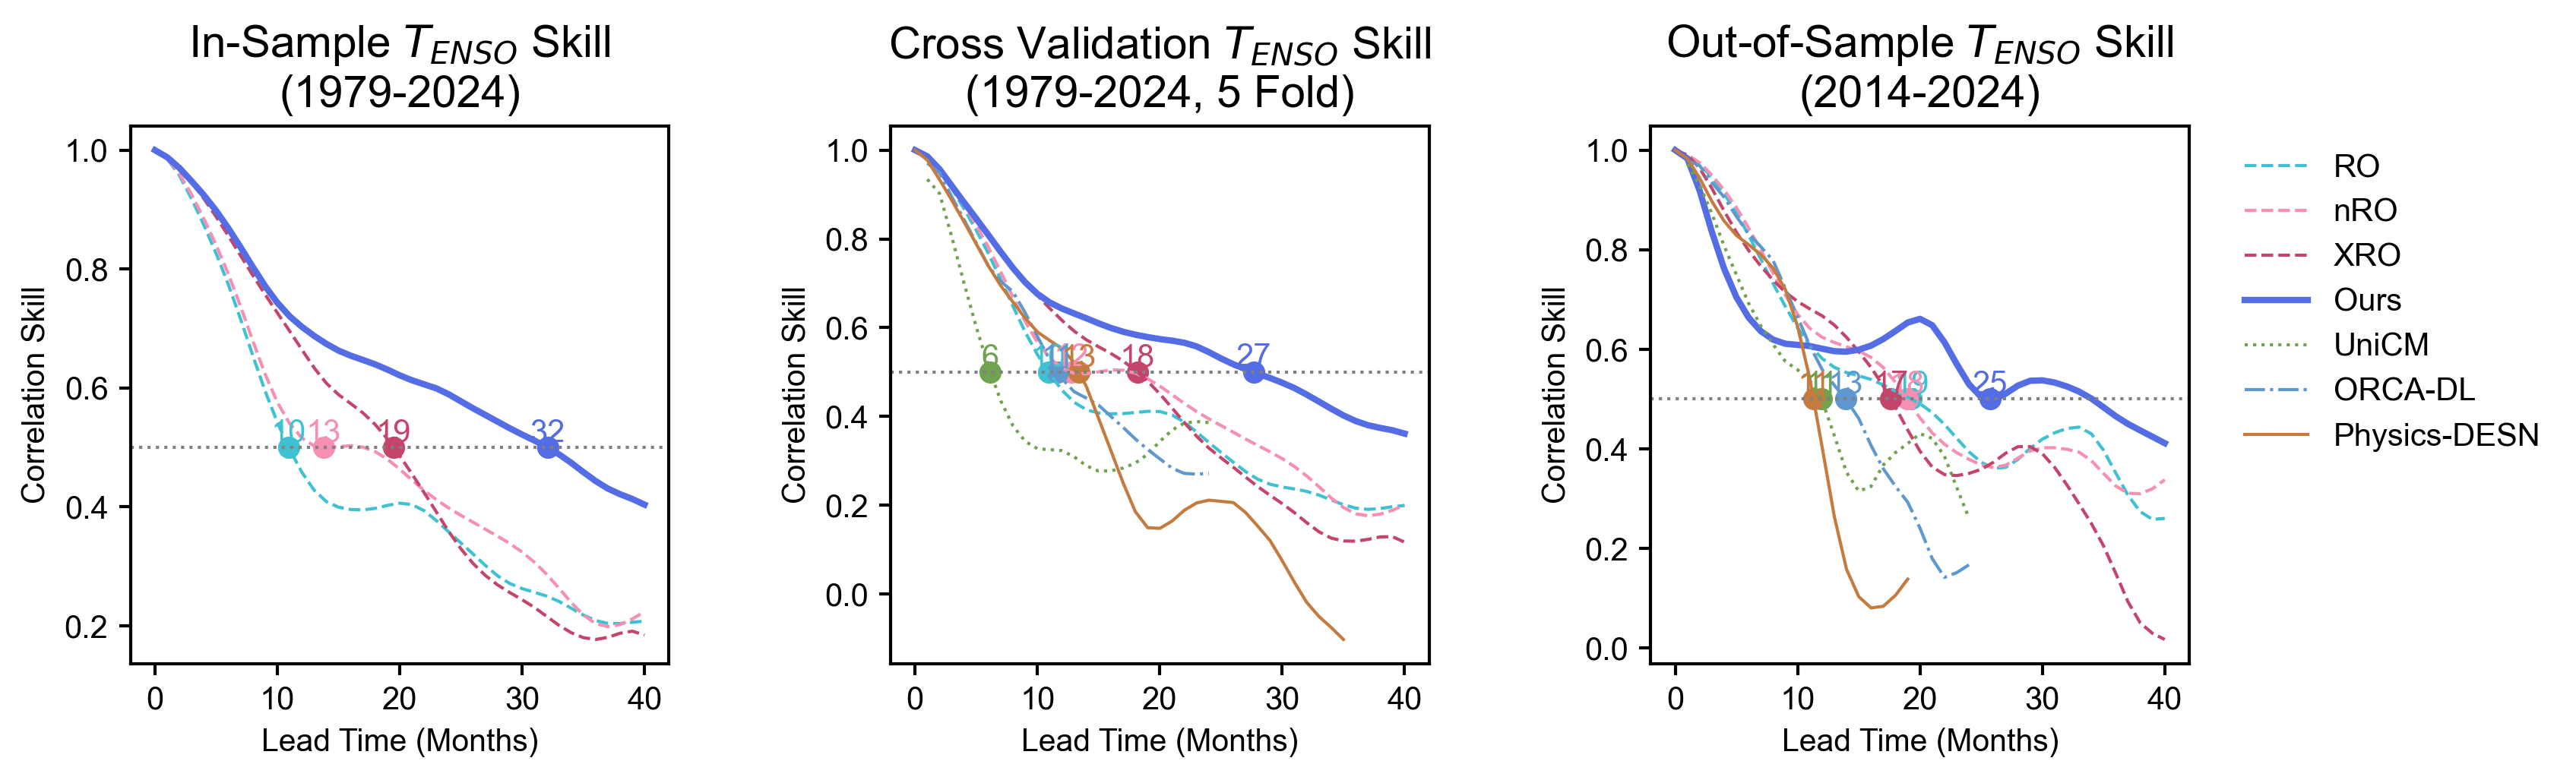

In [26]:
fi, fig, axes = get_fig(1, 3, AW=6, A_ratio=1.0, LM=5, RM=5, TM=5, BM=5, HS=5, VS=5, dpi=300, fontsize=14, lw=1)
ax_loader = iter(axes)
var = 'x'
mode = 'ENSO'
var_map = {'x': 'T', 'h': 'h'}

if True: # 1979-2024 In-Sample
    ax = next(ax_loader)

    corr_RO = est.evaluator.get_skills(detail_insample_RO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_nRO = est.evaluator.get_skills(detail_insample_nRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_XRO = est.evaluator.get_skills(detail_insample_XRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_ours = est.evaluator.get_skills(detail_insample_ours['PREDICTION'], return_raw=True)[(var, mode)]

    ax.plot(corr_RO.index, corr_RO.values, label='RO', color='#3dc1d3', linestyle='--')
    ax.plot(corr_nRO.index, corr_nRO.values, label='nRO', color='#f78fb3', linestyle='--')
    ax.plot(corr_XRO.index, corr_XRO.values, label='XRO', color='#c44569', linestyle='--')
    ax.plot(corr_ours.index, corr_ours.values, label='Ours', color='#546de5', linestyle='-', lw=2)

    ax.scatter(s := get_skill(corr_RO), 0.5, color='#3dc1d3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#3dc1d3')
    ax.scatter(s := get_skill(corr_nRO), 0.5, color='#f78fb3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#f78fb3')
    ax.scatter(s := get_skill(corr_XRO), 0.5, color='#c44569', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c44569')
    ax.scatter(s := get_skill(corr_ours), 0.5, color='#546de5', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#546de5')

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
    ax.set_xlabel('Lead Time (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Correlation Skill', fontsize=0.7*fi['fontsize'])
    ax.set_title(f'In-Sample ${var_map[var]}_{{{mode}}}$ Skill\n(1979-2024)')
    # ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

if True: # 1979-2024 5-Fold Cross Validation
    ax = next(ax_loader)

    corr_RO = est.evaluator.get_skills(detail_5fold_cv_RO['PREDICTION_cv'], return_raw=True)[(var, mode)]
    corr_nRO = est.evaluator.get_skills(detail_5fold_cv_nRO['PREDICTION_cv'], return_raw=True)[(var, mode)]
    corr_XRO = est.evaluator.get_skills(detail_5fold_cv_XRO['PREDICTION_cv'], return_raw=True)[(var, mode)]
    corr_ours = est.evaluator.get_skills(detail_5fold_cv_ours['PREDICTION_cv'], return_raw=True)[(var, mode)]
    df_tmp = pd.read_csv('./data/baseline/ORCA-DL/corr_197901-202412_5fold.csv')
    corr_ORCA_DL = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/Physics-DESN/corr_197901-202412_5fold.csv')
    corr_Physics_DESN = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/UniCM/corr_197901-202412_5fold.csv')
    corr_UniCM = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']

    ax.plot(corr_RO.index, corr_RO.values, label='RO', color='#3dc1d3', linestyle='--')
    ax.plot(corr_nRO.index, corr_nRO.values, label='nRO', color='#f78fb3', linestyle='--')
    ax.plot(corr_XRO.index, corr_XRO.values, label='XRO', color='#c44569', linestyle='--')
    ax.plot(corr_ours.index, corr_ours.values, label='Ours', color='#546de5', linestyle='-', lw=2)
    ax.plot(corr_UniCM.index, corr_UniCM.values, label='UniCM', color='#70a350', linestyle=':')
    ax.plot(corr_ORCA_DL.index, corr_ORCA_DL.values, label='ORCA-DL', color='#5f98ce', linestyle='-.')
    ax.plot(corr_Physics_DESN.index, corr_Physics_DESN.values, label='Physics-DESN', color='#c57b3e', linestyle='-')

    ax.scatter(s := get_skill(corr_RO), 0.5, color='#3dc1d3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#3dc1d3')
    ax.scatter(s := get_skill(corr_nRO), 0.5, color='#f78fb3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#f78fb3')
    ax.scatter(s := get_skill(corr_XRO), 0.5, color='#c44569', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c44569')
    ax.scatter(s := get_skill(corr_ours), 0.5, color='#546de5', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#546de5')
    ax.scatter(s := get_skill(corr_UniCM), 0.5, color='#70a350', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#70a350')
    ax.scatter(s := get_skill(corr_ORCA_DL), 0.5, color='#5f98ce', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#5f98ce')
    ax.scatter(s := get_skill(corr_Physics_DESN), 0.5, color='#c57b3e', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c57b3e')

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
    ax.set_xlabel('Lead Time (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Correlation Skill', fontsize=0.7*fi['fontsize'])
    ax.set_title(f'Cross Validation ${var_map[var]}_{{{mode}}}$ Skill\n(1979-2024, 5 Fold)')
    # ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

if True: # 2014-2024 Out-Sample
    ax = next(ax_loader)

    corr_RO = est.evaluator.get_skills(detail_outsample_RO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_nRO = est.evaluator.get_skills(detail_outsample_nRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_XRO = est.evaluator.get_skills(detail_outsample_XRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_ours = est.evaluator.get_skills(detail_outsample_ours['PREDICTION'], return_raw=True)[(var, mode)]
    df_tmp = pd.read_csv('./data/baseline/ORCA-DL/corr_201401-202312_outsample.csv')
    corr_ORCA_DL = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/Physics-DESN/corr_201401-202401_outsample.csv')
    corr_Physics_DESN = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/UniCM/corr_201401-202412_outsample.csv')
    corr_UniCM = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']

    ax.plot(corr_RO.index, corr_RO.values, label='RO', color='#3dc1d3', linestyle='--')
    ax.plot(corr_nRO.index, corr_nRO.values, label='nRO', color='#f78fb3', linestyle='--')
    ax.plot(corr_XRO.index, corr_XRO.values, label='XRO', color='#c44569', linestyle='--')
    ax.plot(corr_ours.index, corr_ours.values, label='Ours', color='#546de5', linestyle='-', lw=2)
    ax.plot(corr_UniCM.index, corr_UniCM.values, label='UniCM', color='#70a350', linestyle=':')
    ax.plot(corr_ORCA_DL.index, corr_ORCA_DL.values, label='ORCA-DL', color='#5f98ce', linestyle='-.')
    ax.plot(corr_Physics_DESN.index, corr_Physics_DESN.values, label='Physics-DESN', color='#c57b3e', linestyle='-')

    ax.scatter(s := get_skill(corr_RO), 0.5, color='#3dc1d3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#3dc1d3')
    ax.scatter(s := get_skill(corr_nRO), 0.5, color='#f78fb3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#f78fb3')
    ax.scatter(s := get_skill(corr_XRO), 0.5, color='#c44569', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c44569')
    ax.scatter(s := get_skill(corr_ours), 0.5, color='#546de5', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#546de5')
    ax.scatter(s := get_skill(corr_UniCM), 0.5, color='#70a350', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#70a350')
    ax.scatter(s := get_skill(corr_ORCA_DL), 0.5, color='#5f98ce', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#5f98ce')
    ax.scatter(s := get_skill(corr_Physics_DESN), 0.5, color='#c57b3e', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c57b3e')

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
    ax.set_xlabel('Lead Time (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Correlation Skill', fontsize=0.7*fi['fontsize'])
    ax.set_title(f'Out-of-Sample ${var_map[var]}_{{{mode}}}$ Skill\n(2014-2024)')
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

fig.savefig(save_dir / f'Fig2b-d-f-1.png', transparent=True, dpi=300, bbox_inches='tight')
fig.savefig(save_dir / f'Fig2b-d-f-1.svg', transparent=True, dpi=300, bbox_inches='tight')
fig.savefig(save_dir / f'Fig2b-d-f-1.pdf', transparent=True, dpi=300, bbox_inches='tight')


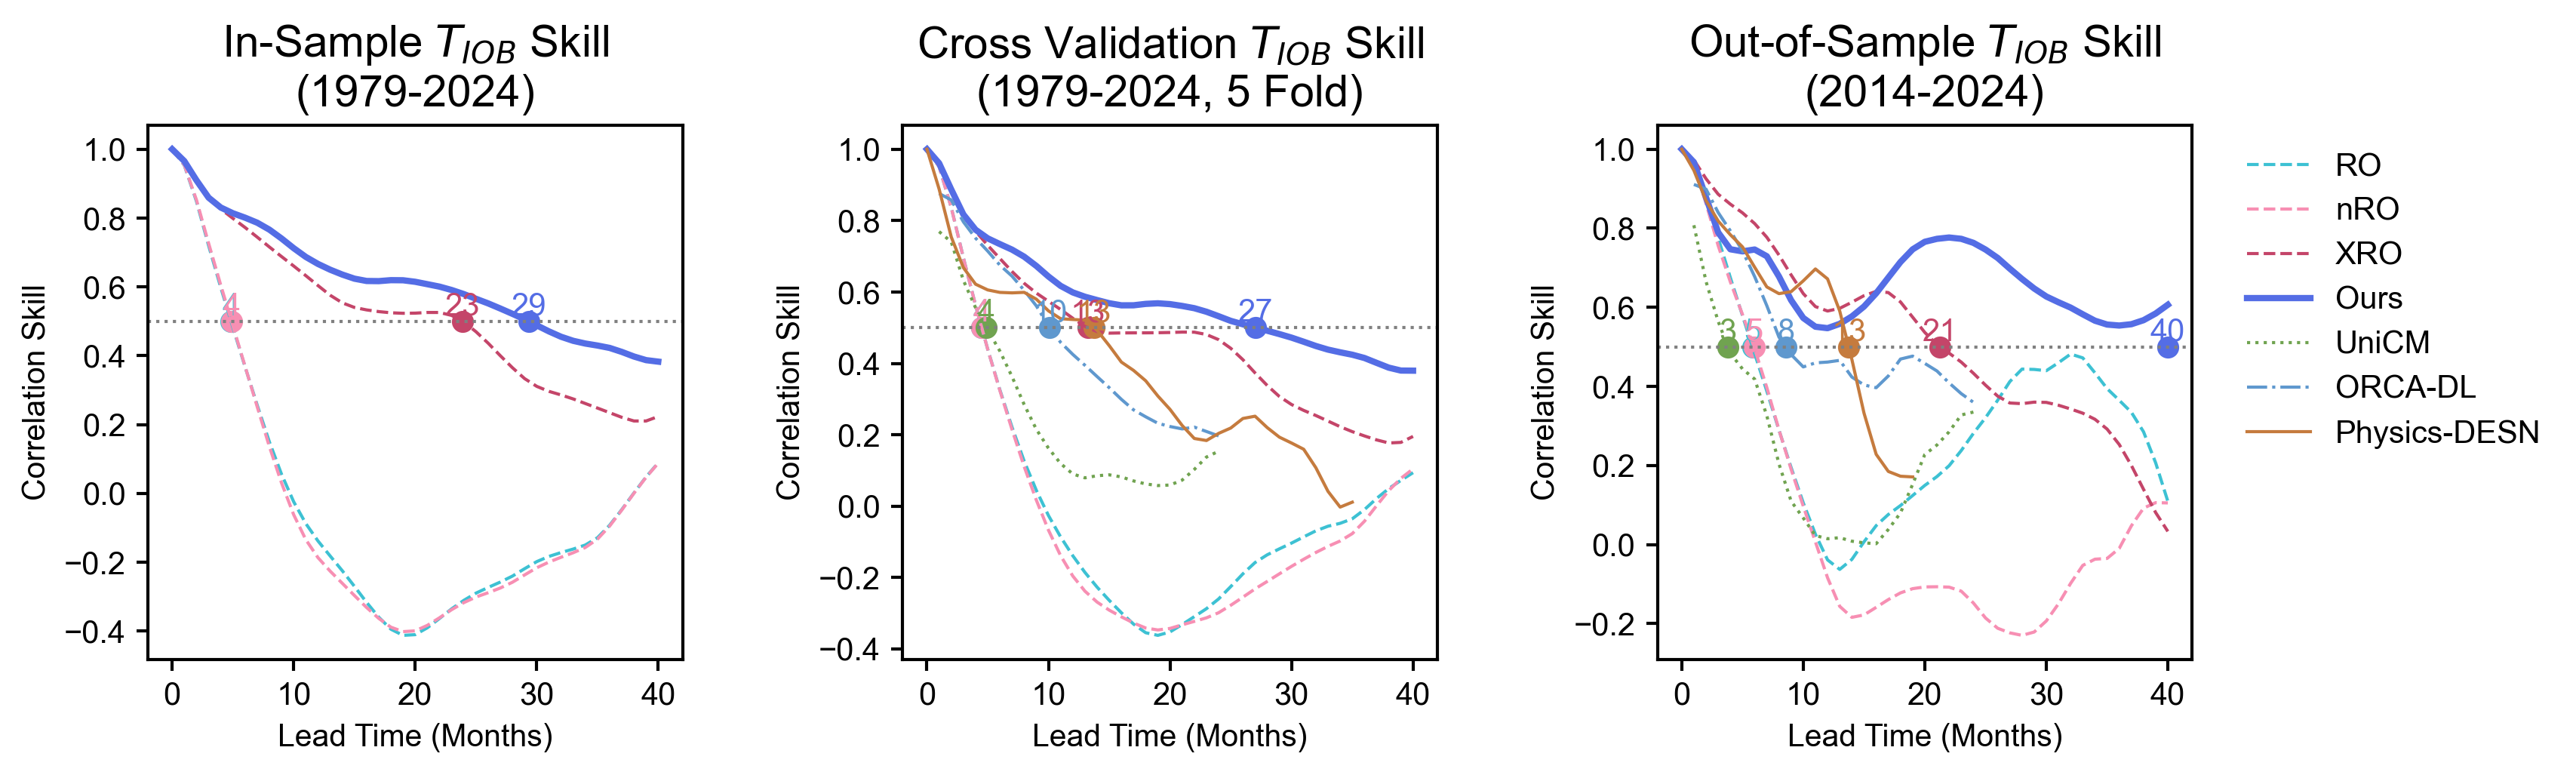

In [31]:
fi, fig, axes = get_fig(1, 3, AW=6, A_ratio=1.0, LM=5, RM=5, TM=5, BM=5, HS=5, VS=5, dpi=300, fontsize=14, lw=1)
ax_loader = iter(axes)
var = 'x'
mode = 'IOB'
var_map = {'x': 'T', 'h': 'h'}

if True: # 1979-2024 In-Sample
    ax = next(ax_loader)

    corr_RO = est.evaluator.get_skills(detail_insample_RO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_nRO = est.evaluator.get_skills(detail_insample_nRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_XRO = est.evaluator.get_skills(detail_insample_XRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_ours = est.evaluator.get_skills(detail_insample_ours['PREDICTION'], return_raw=True)[(var, mode)]

    ax.plot(corr_RO.index, corr_RO.values, label='RO', color='#3dc1d3', linestyle='--')
    ax.plot(corr_nRO.index, corr_nRO.values, label='nRO', color='#f78fb3', linestyle='--')
    ax.plot(corr_XRO.index, corr_XRO.values, label='XRO', color='#c44569', linestyle='--')
    ax.plot(corr_ours.index, corr_ours.values, label='Ours', color='#546de5', linestyle='-', lw=2)

    ax.scatter(s := get_skill(corr_RO), 0.5, color='#3dc1d3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#3dc1d3')
    ax.scatter(s := get_skill(corr_nRO), 0.5, color='#f78fb3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#f78fb3')
    ax.scatter(s := get_skill(corr_XRO), 0.5, color='#c44569', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c44569')
    ax.scatter(s := get_skill(corr_ours), 0.5, color='#546de5', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#546de5')

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
    ax.set_xlabel('Lead Time (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Correlation Skill', fontsize=0.7*fi['fontsize'])
    ax.set_title(f'In-Sample ${var_map[var]}_{{{mode}}}$ Skill\n(1979-2024)')
    # ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

if True: # 1979-2024 5-Fold Cross Validation
    ax = next(ax_loader)

    corr_RO = est.evaluator.get_skills(detail_5fold_cv_RO['PREDICTION_cv'], return_raw=True)[(var, mode)]
    corr_nRO = est.evaluator.get_skills(detail_5fold_cv_nRO['PREDICTION_cv'], return_raw=True)[(var, mode)]
    corr_XRO = est.evaluator.get_skills(detail_5fold_cv_XRO['PREDICTION_cv'], return_raw=True)[(var, mode)]
    corr_ours = est.evaluator.get_skills(detail_5fold_cv_ours['PREDICTION_cv'], return_raw=True)[(var, mode)]
    df_tmp = pd.read_csv('./data/baseline/ORCA-DL/corr_197901-202412_5fold.csv')
    corr_ORCA_DL = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/Physics-DESN/corr_197901-202412_5fold.csv')
    corr_Physics_DESN = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/UniCM/corr_197901-202412_5fold.csv')
    corr_UniCM = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']

    ax.plot(corr_RO.index, corr_RO.values, label='RO', color='#3dc1d3', linestyle='--')
    ax.plot(corr_nRO.index, corr_nRO.values, label='nRO', color='#f78fb3', linestyle='--')
    ax.plot(corr_XRO.index, corr_XRO.values, label='XRO', color='#c44569', linestyle='--')
    ax.plot(corr_ours.index, corr_ours.values, label='Ours', color='#546de5', linestyle='-', lw=2)
    ax.plot(corr_UniCM.index, corr_UniCM.values, label='UniCM', color='#70a350', linestyle=':')
    ax.plot(corr_ORCA_DL.index, corr_ORCA_DL.values, label='ORCA-DL', color='#5f98ce', linestyle='-.')
    ax.plot(corr_Physics_DESN.index, corr_Physics_DESN.values, label='Physics-DESN', color='#c57b3e', linestyle='-')

    ax.scatter(s := get_skill(corr_RO), 0.5, color='#3dc1d3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#3dc1d3')
    ax.scatter(s := get_skill(corr_nRO), 0.5, color='#f78fb3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#f78fb3')
    ax.scatter(s := get_skill(corr_XRO), 0.5, color='#c44569', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c44569')
    ax.scatter(s := get_skill(corr_ours), 0.5, color='#546de5', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#546de5')
    ax.scatter(s := get_skill(corr_UniCM), 0.5, color='#70a350', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#70a350')
    ax.scatter(s := get_skill(corr_ORCA_DL), 0.5, color='#5f98ce', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#5f98ce')
    ax.scatter(s := get_skill(corr_Physics_DESN), 0.5, color='#c57b3e', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c57b3e')

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
    ax.set_xlabel('Lead Time (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Correlation Skill', fontsize=0.7*fi['fontsize'])
    ax.set_title(f'Cross Validation ${var_map[var]}_{{{mode}}}$ Skill\n(1979-2024, 5 Fold)')
    # ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

if True: # 2014-2024 Out-Sample
    ax = next(ax_loader)

    corr_RO = est.evaluator.get_skills(detail_outsample_RO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_nRO = est.evaluator.get_skills(detail_outsample_nRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_XRO = est.evaluator.get_skills(detail_outsample_XRO['PREDICTION'], return_raw=True)[(var, mode)]
    corr_ours = est.evaluator.get_skills(detail_outsample_ours['PREDICTION'], return_raw=True)[(var, mode)]
    df_tmp = pd.read_csv('./data/baseline/ORCA-DL/corr_201401-202312_outsample.csv')
    corr_ORCA_DL = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/Physics-DESN/corr_201401-202401_outsample.csv')
    corr_Physics_DESN = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']
    df_tmp = pd.read_csv('./data/baseline/UniCM/corr_201401-202412_outsample.csv')
    corr_UniCM = df_tmp.set_index(['mode', 'lead']).loc[mode]['corr']

    ax.plot(corr_RO.index, corr_RO.values, label='RO', color='#3dc1d3', linestyle='--')
    ax.plot(corr_nRO.index, corr_nRO.values, label='nRO', color='#f78fb3', linestyle='--')
    ax.plot(corr_XRO.index, corr_XRO.values, label='XRO', color='#c44569', linestyle='--')
    ax.plot(corr_ours.index, corr_ours.values, label='Ours', color='#546de5', linestyle='-', lw=2)
    ax.plot(corr_UniCM.index, corr_UniCM.values, label='UniCM', color='#70a350', linestyle=':')
    ax.plot(corr_ORCA_DL.index, corr_ORCA_DL.values, label='ORCA-DL', color='#5f98ce', linestyle='-.')
    ax.plot(corr_Physics_DESN.index, corr_Physics_DESN.values, label='Physics-DESN', color='#c57b3e', linestyle='-')

    ax.scatter(s := get_skill(corr_RO), 0.5, color='#3dc1d3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#3dc1d3')
    ax.scatter(s := get_skill(corr_nRO), 0.5, color='#f78fb3', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#f78fb3')
    ax.scatter(s := get_skill(corr_XRO), 0.5, color='#c44569', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c44569')
    ax.scatter(s := get_skill(corr_ours), 0.5, color='#546de5', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#546de5')
    ax.scatter(s := get_skill(corr_UniCM), 0.5, color='#70a350', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#70a350')
    ax.scatter(s := get_skill(corr_ORCA_DL), 0.5, color='#5f98ce', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#5f98ce')
    ax.scatter(s := get_skill(corr_Physics_DESN), 0.5, color='#c57b3e', marker='o')
    ax.annotate(f'{int(s)}', (s, 0.5), ha='center', va='bottom', fontsize=10, color='#c57b3e')

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=1)
    ax.set_xlabel('Lead Time (Months)', fontsize=0.7*fi['fontsize'])
    ax.set_ylabel('Correlation Skill', fontsize=0.7*fi['fontsize'])
    ax.set_title(f'Out-of-Sample ${var_map[var]}_{{{mode}}}$ Skill\n(2014-2024)')
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False)

fig.savefig(save_dir / f'Fig2b-d-f-2.png', transparent=True, dpi=300, bbox_inches='tight')
fig.savefig(save_dir / f'Fig2b-d-f-2.svg', transparent=True, dpi=300, bbox_inches='tight')
fig.savefig(save_dir / f'Fig2b-d-f-2.pdf', transparent=True, dpi=300, bbox_inches='tight')
